In [1]:
import numpy as np, pandas as pd, time
from numba import njit

rng = np.random.default_rng(0)
N = 10_000_000          # 10 million keys per dataset (80 MB each, larger than CPU cache)

def make_keys(kind):
    if kind == "uniform":
        k = rng.uniform(0, 1e12, N)
    elif kind == "normal":
        k = rng.normal(5e11, 1e11, N)
    elif kind == "lognormal":
        k = rng.lognormal(0, 2, N) * 1e9
    elif kind == "clustered":
        centers = rng.uniform(0, 1e12, 20)
        k = rng.choice(centers, N) + rng.normal(0, 1e8, N)
    return np.unique(k)     # sorted, unique keys

datasets = {kind: make_keys(kind) for kind in ["uniform", "normal", "lognormal", "clustered"]}
for name, keys in datasets.items():
    print(f"{name:10s}: {len(keys):,} keys, range {keys[0]:.3g} to {keys[-1]:.3g}")

uniform   : 10,000,000 keys, range 3.39e+04 to 1e+12
normal    : 10,000,000 keys, range -8.55e+09 to 1.02e+12
lognormal : 10,000,000 keys, range 4.12e+04 to 4.24e+13
clustered : 10,000,000 keys, range 1.69e+10 to 9.32e+11


In [2]:
@njit
def binary_search_batch(keys, queries):
    out = np.empty(queries.shape[0], np.int64)
    n = keys.shape[0]
    for i in range(queries.shape[0]):
        q = queries[i]
        lo, hi = 0, n
        while lo < hi:
            mid = (lo + hi) >> 1
            if keys[mid] < q:
                lo = mid + 1
            else:
                hi = mid
        out[i] = lo
    return out

def time_it(fn, *args, repeats=3):
    """Run once to compile, then return the best of several timed runs."""
    fn(*args)
    best = float("inf")
    for _ in range(repeats):
        t = time.perf_counter()
        out = fn(*args)
        best = min(best, time.perf_counter() - t)
    return best, out

# Quick check
keys = datasets["uniform"]
idx = rng.integers(0, len(keys), 1_000_000)
t, out = time_it(binary_search_batch, keys, keys[idx])
print("Correct:", np.array_equal(out, idx), f"| {t / len(idx) * 1e9:.0f} ns per lookup")

Correct: True | 451 ns per lookup


In [7]:
def build_rmi(keys, M, top="lsq"):
    n = len(keys)
    kmin, kmax = keys[0], keys[-1]
    u = (keys - kmin) / (kmax - kmin)
    pos = np.arange(n, dtype=np.float64)

    # Top model: maps a key to a leaf number
    if top == "lsq":
        a0, b0 = np.polyfit(u, pos * M / n, 1)    # least-squares line (original)
    else:
        a0, b0 = float(M), 0.0                    # min-max routing: equal slices of the key range
    leaf = np.clip((a0 * u + b0).astype(np.int64), 0, M - 1)

    # Leaves are contiguous because the top model is increasing
    starts = np.searchsorted(leaf, np.arange(M), side="left")
    ends = np.searchsorted(leaf, np.arange(M), side="right")
    nonempty = ends > starts
    s = starts[nonempty]
    cnt = (ends - starts)[nonempty].astype(np.float64)
    j = (np.cumsum(nonempty) - 1)[leaf]            # each key's index among non-empty leaves

    # Leaf models: least-squares line per leaf (centered for numerical stability)
    xc, yc = keys - keys[s][j], pos - s[j]
    mx = np.add.reduceat(xc, s) / cnt
    my = np.add.reduceat(yc, s) / cnt
    dx, dy = xc - mx[j], yc - my[j]
    sxx = np.add.reduceat(dx * dx, s)
    sxy = np.add.reduceat(dx * dy, s)
    slope_ne = np.where(sxx > 0, sxy / np.where(sxx > 0, sxx, 1), 0.0)
    bx_ne, by_ne = keys[s] + mx, s + my

    # Per-leaf error bounds (with a safety margin of 1)
    err = pos - (by_ne[j] + slope_ne[j] * (keys - bx_ne[j]))
    lo_ne = np.floor(np.minimum.reduceat(err, s)).astype(np.int64) - 1
    hi_ne = np.ceil(np.maximum.reduceat(err, s)).astype(np.int64) + 1

    # Fill arrays for all M leaves (empty leaves get trivial values)
    base_x, slope = np.zeros(M), np.zeros(M)
    base_y = starts.astype(np.float64)
    lo_err, hi_err = np.zeros(M, np.int64), np.zeros(M, np.int64)
    base_x[nonempty], base_y[nonempty], slope[nonempty] = bx_ne, by_ne, slope_ne
    lo_err[nonempty], hi_err[nonempty] = lo_ne, hi_ne

    window = (np.minimum(hi_ne - lo_ne, n) * cnt).sum() / n   # average search window, capped at n
    size_kb = M * 5 * 8 / 1024                                 # 5 numbers per leaf, 8 bytes each
    params = (kmin, kmax, a0, b0, M, base_x, base_y, slope, lo_err, hi_err)
    return params, window, size_kb

In [4]:
@njit
def rmi_lookup_batch(keys, queries, kmin, kmax, a0, b0, M,
                     base_x, base_y, slope, lo_err, hi_err):
    n = keys.shape[0]
    out = np.empty(queries.shape[0], np.int64)
    fallbacks = 0
    for i in range(queries.shape[0]):
        q = queries[i]
        j = int(a0 * ((q - kmin) / (kmax - kmin)) + b0)     # top model: pick a leaf
        if j < 0: j = 0
        elif j >= M: j = M - 1
        p = int(base_y[j] + slope[j] * (q - base_x[j]))     # leaf model: predict position
        lo, hi = p + lo_err[j], p + hi_err[j] + 1           # search only inside the error window
        if lo < 0: lo = 0
        if hi > n: hi = n
        while lo < hi:
            mid = (lo + hi) >> 1
            if keys[mid] < q:
                lo = mid + 1
            else:
                hi = mid
        if lo >= n or keys[lo] != q:                        # safety net: full binary search
            fallbacks += 1
            lo, hi = 0, n
            while lo < hi:
                mid = (lo + hi) >> 1
                if keys[mid] < q:
                    lo = mid + 1
                else:
                    hi = mid
        out[i] = lo
    return out, fallbacks

In [5]:
Ms = [1, 10, 100, 1_000, 10_000, 100_000]
rows = []
for name, keys in datasets.items():
    idx = rng.integers(0, len(keys), 1_000_000)
    q = keys[idx]

    t, out = time_it(binary_search_batch, keys, q)
    assert np.array_equal(out, idx)
    rows.append(dict(data=name, method="Binary search", M=0,
                     ns_per_lookup=t / len(q) * 1e9, avg_window=len(keys), size_kb=0, fallbacks=0))

    for M in Ms:
        params, window, size_kb = build_rmi(keys, M)
        t, (out, fb) = time_it(rmi_lookup_batch, keys, q, *params)
        assert np.array_equal(out, idx), "Wrong result!"
        rows.append(dict(data=name, method="Learned index", M=M,
                         ns_per_lookup=t / len(q) * 1e9, avg_window=window, size_kb=size_kb, fallbacks=fb))
    print(f"{name} done")

res = pd.DataFrame(rows)
pd.set_option("display.float_format", lambda v: f"{v:,.1f}")
print(res.to_string(index=False))

uniform done
normal done
lognormal done
clustered done
     data        method      M  ns_per_lookup    avg_window  size_kb  fallbacks
  uniform Binary search      0          466.3  10,000,000.0      0.0          0
  uniform Learned index      1          382.9       3,150.0      0.0          0
  uniform Learned index     10          323.6       1,182.8      0.4          0
  uniform Learned index    100          251.5         374.7      3.9          0
  uniform Learned index   1000          202.5         119.6     39.1          0
  uniform Learned index  10000          150.4          39.2    390.6          0
  uniform Learned index 100000          119.0          13.6  3,906.2          0
   normal Binary search      0          446.8  10,000,000.0      0.0          0
   normal Learned index      1          545.9  19,141,155.0      0.0          0
   normal Learned index     10          554.1     245,695.1      0.4          0
   normal Learned index    100          316.3      61,927.1      

In [6]:
def leaf_diagnostics(keys, M):
    n = len(keys)
    u = (keys - keys[0]) / (keys[-1] - keys[0])
    a0, b0 = np.polyfit(u, np.arange(n) * M / n, 1)
    raw = (a0 * u + b0).astype(np.int64)
    leaf = np.clip(raw, 0, M - 1)
    first, last = (leaf == 0).mean(), (leaf == M - 1).mean()
    clipped = ((raw < 0) | (raw > M - 1)).mean()
    return first, last, clipped

M = 100_000
print(f"{'data':10s} {'% in first leaf':>16s} {'% in last leaf':>15s} {'% clipped':>10s}")
for name, keys in datasets.items():
    f, l, c = leaf_diagnostics(keys, M)
    print(f"{name:10s} {100*f:15.2f}% {100*l:14.2f}% {100*c:9.2f}%")

data        % in first leaf  % in last leaf  % clipped
uniform               0.00%           0.01%      0.01%
normal                3.82%           3.82%      7.64%
lognormal             0.00%           0.12%      0.12%
clustered             0.00%          10.00%     10.00%


In [8]:
rows2 = []
for name, keys in datasets.items():
    idx = rng.integers(0, len(keys), 1_000_000)
    q = keys[idx]
    for top in ["lsq", "minmax"]:
        for M in [1_000, 10_000, 100_000]:
            params, window, size_kb = build_rmi(keys, M, top)
            t, (out, fb) = time_it(rmi_lookup_batch, keys, q, *params)
            assert np.array_equal(out, idx), "Wrong result!"
            rows2.append(dict(data=name, top=top, M=M, ns_per_lookup=t / len(q) * 1e9,
                              avg_window=window, fallbacks=fb))
    print(f"{name} done")

res2 = pd.DataFrame(rows2)
print(res2.pivot_table(index=["data", "M"], columns="top",
                       values=["ns_per_lookup", "avg_window"]).round(1).to_string())

uniform done
normal done
lognormal done
clustered done
                 avg_window             ns_per_lookup       
top                     lsq      minmax           lsq minmax
data      M                                                 
clustered 1000    501,719.9   596,928.4         723.5  747.4
          10000    57,724.6     9,669.4         575.2  478.8
          100000   49,597.4       172.2         257.7  272.2
lognormal 1000    362,575.9 9,220,567.3         694.0  842.7
          10000    11,373.8 2,690,574.2         371.6  787.0
          100000      380.2   207,378.4         223.9  539.7
normal    1000     53,629.1       198.2         330.1  225.4
          10000    52,811.4        64.4         191.0  174.6
          100000   52,713.3        21.4         164.0  134.9
uniform   1000        119.6       118.8         203.3  214.7
          10000        39.2        39.3         161.6  164.7
          100000       13.6        13.6         167.4  132.9


uniform done
normal done
lognormal done
clustered done


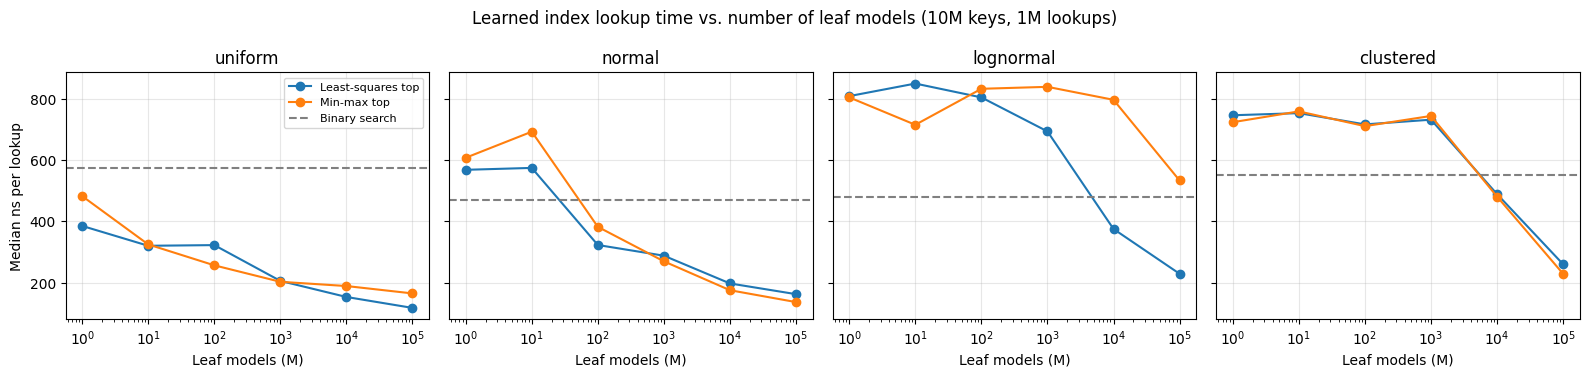

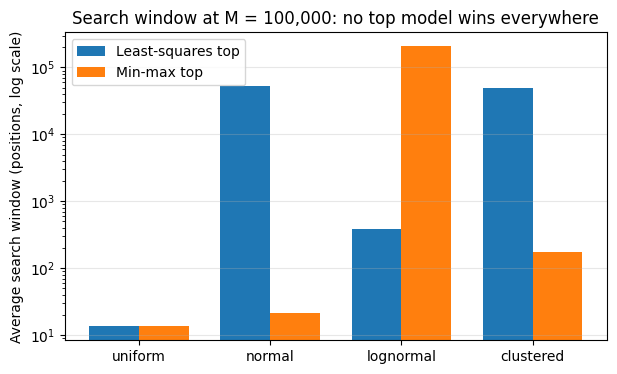

     data    top      M    ns       window
  uniform binary      0 575.2 10,000,000.0
  uniform    lsq 100000 118.2         13.6
  uniform minmax 100000 165.4         13.6
   normal binary      0 469.2 10,000,000.0
   normal    lsq 100000 163.0     52,713.3
   normal minmax 100000 137.1         21.4
lognormal binary      0 479.7 10,000,000.0
lognormal    lsq 100000 229.4        380.2
lognormal minmax 100000 533.8    207,378.4
clustered binary      0 550.7 10,000,000.0
clustered    lsq 100000 260.5     49,597.4
clustered minmax 100000 229.3        172.2


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [9]:
import matplotlib.pyplot as plt

def time_median(fn, *args, repeats=7):
    fn(*args)                                   # compile / warm up
    ts = []
    for _ in range(repeats):
        t = time.perf_counter(); out = fn(*args); ts.append(time.perf_counter() - t)
    return np.median(ts), out

Ms = [1, 10, 100, 1_000, 10_000, 100_000]
rows3 = []
for name, keys in datasets.items():
    idx = rng.integers(0, len(keys), 1_000_000)
    q = keys[idx]
    t, _ = time_median(binary_search_batch, keys, q)
    rows3.append(dict(data=name, top="binary", M=0, ns=t / len(q) * 1e9, window=len(keys)))
    for top in ["lsq", "minmax"]:
        for M in Ms:
            params, window, _ = build_rmi(keys, M, top)
            t, (out, fb) = time_median(rmi_lookup_batch, keys, q, *params)
            assert np.array_equal(out, idx) and fb == 0
            rows3.append(dict(data=name, top=top, M=M, ns=t / len(q) * 1e9, window=window))
    print(f"{name} done")
res3 = pd.DataFrame(rows3)

# Figure 1: lookup time vs number of leaf models
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8), sharey=True)
for ax, name in zip(axes, datasets):
    d = res3[res3.data == name]
    for top, label in [("lsq", "Least-squares top"), ("minmax", "Min-max top")]:
        dd = d[d.top == top]
        ax.plot(dd.M, dd.ns, marker="o", label=label)
    ax.axhline(d[d.top == "binary"].ns.iloc[0], color="gray", linestyle="--", label="Binary search")
    ax.set_xscale("log"); ax.set_title(name); ax.set_xlabel("Leaf models (M)"); ax.grid(alpha=0.3)
axes[0].set_ylabel("Median ns per lookup"); axes[0].legend(fontsize=8)
plt.suptitle("Learned index lookup time vs. number of leaf models (10M keys, 1M lookups)")
plt.tight_layout(); plt.savefig("lookup_time.png", dpi=200, bbox_inches="tight"); plt.show()

# Figure 2: average search window at M = 100,000 (log scale)
d = res3[res3.M == 100_000].pivot(index="data", columns="top", values="window").loc[list(datasets)]
x = np.arange(len(d)); w = 0.38
plt.figure(figsize=(7, 4))
plt.bar(x - w/2, d["lsq"], w, label="Least-squares top")
plt.bar(x + w/2, d["minmax"], w, label="Min-max top")
plt.yscale("log"); plt.xticks(x, d.index); plt.ylabel("Average search window (positions, log scale)")
plt.title("Search window at M = 100,000: no top model wins everywhere")
plt.legend(); plt.grid(alpha=0.3, axis="y")
plt.savefig("search_window.png", dpi=200, bbox_inches="tight"); plt.show()

print(res3[res3.M.isin([0, 100_000])].round(1).to_string(index=False))

from google.colab import files
files.download("lookup_time.png"); files.download("search_window.png")